<a href="https://colab.research.google.com/github/sjadhav7279-boop/AI-ML-Assignments/blob/main/Assignment2(meridian_dataset).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import re

df = pd.read_csv('meridian_daily_sales_raw.csv')
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
df.head()

Shape: (1627, 10)

Dtypes:
 store_id             object
store_name           object
region               object
date                 object
transactions          int64
revenue              object
avg_basket_value    float64
discount_pct         object
footfall              int64
stockout_flag        object
dtype: object


,store_id,store_name,region,date,transactions,revenue,avg_basket_value,discount_pct,footfall,stockout_flag
0,ST-10,MAGNOLIA SQUARE,South,07/03/2026,75,NaN,47.71,38.71096522,374,no
1,ST-13,Highland Court,WEST,27/05/2026,60,4040.14,67.12,15.55684393,528,no
2,ST-16,Redwood Station,West,2026-05-24,74,"$7,132.47",105.29,5.214770493,576,Y
3,ST-14,Golden Valley,West,2026-04-20,49,"$9,117.12",167.74,4.864324242,725,yes
4,ST-04,Silverline Mall,North,04/03/2026,-52,"$2,733.73",2796.60,7.926849185,642,N


In [13]:
df['store_id']   = df['store_id'].str.strip().str.upper()
df['store_name'] = df['store_name'].str.strip().str.title()
df['region']     = df['region'].str.strip().str.title()

print(df['store_id'].nunique(), "unique stores")
print(sorted(df['region'].unique()))

18 unique stores
['North', 'South', 'West']


# New Section

In [14]:
def parse_date(s):
    s = str(s).strip()
    for fmt in ["%Y%m%d", "%Y-%m-%d", "%B %d, %Y", "%d-%b-%y"]:
        try:
            return pd.to_datetime(s, format=fmt)
        except ValueError:
            pass
    m = re.match(r'^(\d{2})/(\d{2})/(\d{4})$', s)
    if m:
        a, b, y = int(m.group(1)), int(m.group(2)), int(m.group(3))
        if a > 12:      day, month = a, b          # unambiguous DD/MM
        elif b > 12:    day, month = b, a          # unambiguous MM/DD
        else:           day, month = a, b          # ambiguous -> ASSUMPTION: DD/MM
        return pd.Timestamp(year=y, month=month, day=day)
    return pd.NaT

df['date'] = df['date'].apply(parse_date)
print("Unparseable dates:", df['date'].isna().sum())
print("Date range:", df['date'].min(), "to", df['date'].max())

Unparseable dates: 0
Date range: 2026-01-03 00:00:00 to 2026-12-05 00:00:00


In [15]:
def parse_date(s):
    s = str(s).strip()
    for fmt in ["%Y%m%d", "%Y-%m-%d", "%B %d, %Y", "%d-%b-%y"]:
        try:
            return pd.to_datetime(s, format=fmt)
        except ValueError:
            pass
    m = re.match(r'^(\d{2})/(\d{2})/(\d{4})$', s)
    if m:
        a, b, y = int(m.group(1)), int(m.group(2)), int(m.group(3))
        if a > 12:      day, month = a, b          # unambiguous DD/MM
        elif b > 12:    day, month = b, a          # unambiguous MM/DD
        else:           day, month = a, b          # ambiguous -> ASSUMPTION: DD/MM
        return pd.Timestamp(year=y, month=month, day=day)
    return pd.NaT

df['date'] = df['date'].apply(parse_date)
print("Unparseable dates:", df['date'].isna().sum())
print("Date range:", df['date'].min(), "to", df['date'].max())

Unparseable dates: 1627
Date range: NaT to NaT


In [16]:
print("Raw values:", df['stockout_flag'].unique())

truthy = {'y', 'yes', 'true', '1'}
df['stockout_flag'] = df['stockout_flag'].str.strip().str.lower().isin(truthy)

print(df['stockout_flag'].value_counts())

Raw values: ['no' 'Y' 'yes' 'N' '0' 'TRUE' '1' 'FALSE']
stockout_flag
False    1132
True      495
Name: count, dtype: int64


In [17]:
before = len(df)

dup_mask = df.duplicated(
    subset=['store_id', 'date', 'transactions', 'avg_basket_value',
            'discount_pct', 'footfall', 'stockout_flag'],
    keep='first'
)
print("Duplicate rows detected:", dup_mask.sum())
print(df.loc[dup_mask, ['store_id','store_name','region','date']])

df = df[~dup_mask].reset_index(drop=True)
after = len(df)
print(f"\nRow count before: {before}  ->  after: {after}")

Duplicate rows detected: 7
     store_id    store_name region date
662     ST-11  Willow Creek  South  NaT
726     ST-11  Willow Creek  South  NaT
973     ST-11  Willow Creek  South  NaT
1180    ST-11  Willow Creek  South  NaT
1251    ST-11  Willow Creek  South  NaT
1334    ST-11  Willow Creek  South  NaT
1535    ST-11  Willow Creek  South  NaT

Row count before: 1627  ->  after: 1620


In [18]:
df['discount_pct'] = pd.to_numeric(df['discount_pct'], errors='coerce')  # 'na' strings -> NaN

df['error_negative_transactions'] = df['transactions'] < 0
df['error_discount_out_of_range'] = (df['discount_pct'] < 0) | (df['discount_pct'] > 100)

print("Negative-transaction rows flagged:", df['error_negative_transactions'].sum())
print("Out-of-range discount rows flagged:", df['error_discount_out_of_range'].sum())

Negative-transaction rows flagged: 14
Out-of-range discount rows flagged: 39


In [19]:
df.to_csv('meridian_cleaned.csv', index=False)
print("Final row count:", len(df))
df.head()

Final row count: 1620


,store_id,store_name,region,date,transactions,revenue,avg_basket_value,discount_pct,footfall,stockout_flag,error_negative_transactions,error_discount_out_of_range
0,ST-10,Magnolia Square,South,NaT,75,NaN,47.71,38.710965,374,False,False,False
1,ST-13,Highland Court,West,NaT,60,4040.14,67.12,15.556844,528,False,False,False
2,ST-16,Redwood Station,West,NaT,74,"$7,132.47",105.29,5.214770,576,True,False,False
3,ST-14,Golden Valley,West,NaT,49,"$9,117.12",167.74,4.864324,725,True,False,False
4,ST-04,Silverline Mall,North,NaT,-52,"$2,733.73",2796.60,7.926849,642,False,True,False


In [20]:
Q1_rev = df['revenue'].quantile(0.25)
Q2_rev = df['revenue'].quantile(0.50)
Q3_rev = df['revenue'].quantile(0.75)
IQR_rev = Q3_rev - Q1_rev
print(f"revenue: Q1={Q1_rev:.2f}  median={Q2_rev:.2f}  Q3={Q3_rev:.2f}  IQR={IQR_rev:.2f}")

# Hand-check against one store
check = df[df['store_id'] == 'ST-18']['revenue'].dropna().sort_values()
print(f"\nHand-check store ST-18 (Ashbrook Plaza), n={len(check)}:")
print(check.values)
print(f"ST-18 median = {check.median():.2f}  (compare to overall median {Q2_rev:.2f} — expected to differ, this just confirms .median() is computing correctly)")

TypeError: unsupported operand type(s) for -: 'str' and 'str'

In [21]:
print(df['revenue'].dtype)
print(df['revenue'].head())

object
0          NaN
1      4040.14
2    $7,132.47
3    $9,117.12
4    $2,733.73
Name: revenue, dtype: object


In [22]:
df['revenue'] = (
    df['revenue']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
)

df['revenue'] = pd.to_numeric(df['revenue'], errors='coerce')

In [23]:
print(df['revenue'].dtype)
print(df['revenue'].head())

float64
0        NaN
1    4040.14
2    7132.47
3    9117.12
4    2733.73
Name: revenue, dtype: float64


In [24]:
Q1_rev = df['revenue'].quantile(0.25)
Q2_rev = df['revenue'].quantile(0.50)
Q3_rev = df['revenue'].quantile(0.75)
IQR_rev = Q3_rev - Q1_rev
print(f"revenue: Q1={Q1_rev:.2f}  median={Q2_rev:.2f}  Q3={Q3_rev:.2f}  IQR={IQR_rev:.2f}")

# Hand-check against one store
check = df[df['store_id'] == 'ST-18']['revenue'].dropna().sort_values()
print(f"\nHand-check store ST-18 (Ashbrook Plaza), n={len(check)}:")
print(check.values)
print(f"ST-18 median = {check.median():.2f}  (compare to overall median {Q2_rev:.2f} — expected to differ, this just confirms .median() is computing correctly)")

revenue: Q1=3581.81  median=4938.47  Q3=6921.70  IQR=3339.89

Hand-check store ST-18 (Ashbrook Plaza), n=76:
[1248.74 1268.69 1396.32 1413.74 1436.07 1545.93 1669.85 1780.11 1780.82
 1785.47 1799.67 1933.75 2006.02 2024.6  2049.47 2121.01 2143.4  2176.53
 2176.76 2184.76 2214.96 2216.2  2241.35 2332.19 2342.76 2368.67 2404.73
 2544.42 2565.56 2581.4  2597.42 2602.01 2635.98 2647.24 2686.1  2727.75
 2742.06 2749.41 2814.28 2821.34 2831.8  2861.57 2895.63 2923.85 2940.05
 3025.33 3043.52 3044.45 3064.25 3073.28 3105.87 3136.42 3146.54 3162.77
 3296.04 3472.66 3502.02 3583.76 3646.08 3727.59 3870.38 3886.56 3957.01
 4037.4  4038.72 4187.92 4242.67 4275.4  4373.38 4904.79 4952.09 5135.14
 5276.99 5545.34 6523.88 7407.38]
ST-18 median = 2781.85  (compare to overall median 4938.47 — expected to differ, this just confirms .median() is computing correctly)


In [25]:
lower_fence = Q1_rev - 1.5 * IQR_rev
upper_fence = Q3_rev + 1.5 * IQR_rev
print(f"Lower fence: {lower_fence:.2f}   Upper fence: {upper_fence:.2f}")
print("(Lower fence is negative, so the fence rule can never flag a low-revenue day here —"
      " every fence outlier in this dataset will be a HIGH one.)")

Lower fence: -1428.03   Upper fence: 11931.55
(Lower fence is negative, so the fence rule can never flag a low-revenue day here — every fence outlier in this dataset will be a HIGH one.)


In [26]:
revenue_outliers = df[(df['revenue'] < lower_fence) | (df['revenue'] > upper_fence)]
print("Count:", len(revenue_outliers))
print(revenue_outliers.groupby('store_name').size().sort_values(ascending=False))
revenue_outliers[['store_id','store_name','date','revenue']].sort_values('revenue', ascending=False)

Count: 60
store_name
Bayfront Commons    15
Sunset Boulevard     9
Coral Bay Outlet     8
Harbor Point         6
Willow Creek         5
Redwood Station      5
Maple Junction       4
Cedar Crossing       3
Summit Corner        3
Golden Valley        1
Riverside Plaza      1
dtype: int64


,store_id,store_name,date,revenue
149,ST-07,Sunset Boulevard,NaT,21721.54
730,ST-07,Sunset Boulevard,NaT,21655.00
805,ST-06,Cedar Crossing,NaT,17917.70
101,ST-07,Sunset Boulevard,NaT,16688.90
1480,ST-07,Sunset Boulevard,NaT,16406.55
1541,ST-12,Bayfront Commons,NaT,15876.48
975,ST-09,Coral Bay Outlet,NaT,15033.05
1477,ST-12,Bayfront Commons,NaT,14992.75
175,ST-07,Sunset Boulevard,NaT,14963.88
591,ST-09,Coral Bay Outlet,NaT,14917.47


In [27]:
Q1_ff, Q3_ff = df['footfall'].quantile([0.25, 0.75])
IQR_ff = Q3_ff - Q1_ff
low_ff, high_ff = Q1_ff - 1.5*IQR_ff, Q3_ff + 1.5*IQR_ff
print(f"footfall: Q1={Q1_ff} Q3={Q3_ff} IQR={IQR_ff} fences=({low_ff:.1f}, {high_ff:.1f})")

ff_outliers = df[(df['footfall'] < low_ff) | (df['footfall'] > high_ff)]
print("\nfootfall outliers flagged:", len(ff_outliers))
print(ff_outliers[['store_id','date','footfall']].sort_values('footfall', ascending=False))
print("\nYes — it catches all 3 genuine sensor-fault days (~40,000+), plus a handful of smaller,"
      " more borderline high-footfall days that get swept up by the same fence.")

footfall: Q1=495.75 Q3=700.25 IQR=204.5 fences=(189.0, 1007.0)

footfall outliers flagged: 9
     store_id date  footfall
975     ST-09  NaT     41631
1185    ST-09  NaT     41562
1085    ST-09  NaT     39530
1161    ST-06  NaT      1083
1009    ST-14  NaT      1045
145     ST-14  NaT      1033
165     ST-02  NaT       185
1278    ST-06  NaT       165
330     ST-15  NaT       121

Yes — it catches all 3 genuine sensor-fault days (~40,000+), plus a handful of smaller, more borderline high-footfall days that get swept up by the same fence.


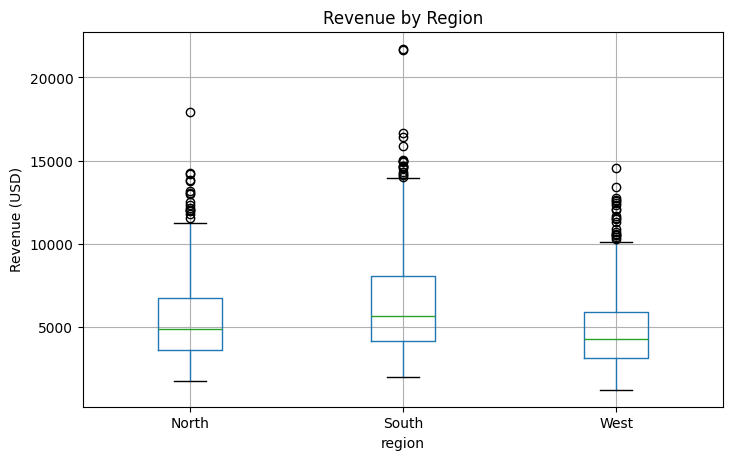

             25%      50%       75%       IQR
region                                       
North   3626.300  4890.38  6752.100  3125.800
South   4144.105  5668.36  8077.815  3933.710
West    3123.590  4275.05  5938.855  2815.265


In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,5))
df.boxplot(column='revenue', by='region', ax=ax)
plt.title('Revenue by Region')
plt.suptitle('')
plt.ylabel('Revenue (USD)')
plt.show()

print(df.groupby('region')['revenue'].describe()[['25%','50%','75%']].assign(
    IQR=lambda x: x['75%'] - x['25%']))

In [29]:
store_stats = df.groupby('store_name')['revenue'].agg(['mean','std']).sort_values('mean', ascending=False)
store_stats['outlier_count'] = df.groupby('store_name')['revenue'].apply(
    lambda s: ((s < lower_fence) | (s > upper_fence)).sum()
)
store_stats

,mean,std,outlier_count
store_name,,,
Bayfront Commons,8719.938961,3259.380698,15
Sunset Boulevard,8022.933421,3806.179803,9
Coral Bay Outlet,7110.316316,2980.939028,8
Willow Creek,6646.579324,2819.677632,5
Maple Junction,6633.822469,2650.885572,4
Harbor Point,6484.997922,2893.038567,6
Redwood Station,6144.946447,2730.990272,5
Golden Valley,5889.539577,2461.005585,1
Summit Corner,5868.202857,2569.485275,3


In [30]:
footfall_clean = df.loc[df['footfall'] < 10000, 'footfall']   # drop the 3 sensor-fault days
Q1_ffc, Q3_ffc = footfall_clean.quantile([0.25, 0.75])
IQR_ffc = Q3_ffc - Q1_ffc
low_ffc, high_ffc = Q1_ffc - 1.5*IQR_ffc, Q3_ffc + 1.5*IQR_ffc

print(f"BEFORE removing sensor faults: fences = ({low_ff:.1f}, {high_ff:.1f})")
print(f"AFTER  removing sensor faults: fences = ({low_ffc:.1f}, {high_ffc:.1f})")
print(f"Shift in upper fence: {high_ff - high_ffc:.1f}")

BEFORE removing sensor faults: fences = (189.0, 1007.0)
AFTER  removing sensor faults: fences = (187.5, 1007.5)
Shift in upper fence: -0.5


In [31]:
mean_rev = df['revenue'].mean()
median_rev = df['revenue'].median()
mode_rev = df['revenue'].mode()

print(f"Mean:   {mean_rev:.2f}")
print(f"Median: {median_rev:.2f}")
print(f"Mode:   {mode_rev.tolist()}")

Mean:   5638.47
Median: 4938.47
Mode:   [4175.45, 5344.68]


In [32]:
skew_rev = df['revenue'].skew()
print(f"Skewness: {skew_rev:.3f}")


Skewness: 1.365


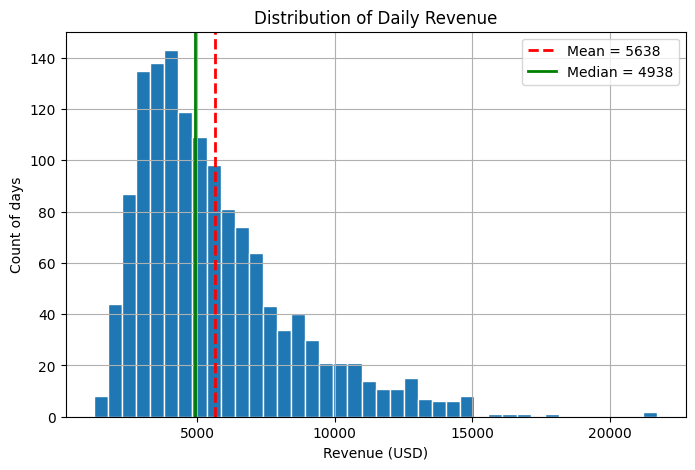

In [33]:
fig, ax = plt.subplots(figsize=(8,5))
df['revenue'].hist(bins=40, ax=ax, edgecolor='white')
ax.axvline(mean_rev, color='red', linestyle='--', linewidth=2, label=f'Mean = {mean_rev:.0f}')
ax.axvline(median_rev, color='green', linestyle='-', linewidth=2, label=f'Median = {median_rev:.0f}')
ax.set_xlabel('Revenue (USD)')
ax.set_ylabel('Count of days')
ax.set_title('Distribution of Daily Revenue')
ax.legend()
plt.show()

In [34]:
skew_ff_before = df['footfall'].skew()
skew_ff_after = footfall_clean.skew()

print(f"footfall skew BEFORE removing sensor faults: {skew_ff_before:.3f}")
print(f"footfall skew AFTER  removing sensor faults: {skew_ff_after:.3f}")

footfall skew BEFORE removing sensor faults: 22.957
footfall skew AFTER  removing sensor faults: 0.025


In [35]:
region_summary = df.groupby('region').apply(lambda g: pd.Series({
    'median_revenue': g['revenue'].median(),
    'IQR_revenue': g['revenue'].quantile(0.75) - g['revenue'].quantile(0.25),
    'outlier_count': ((g['revenue'] < lower_fence) | (g['revenue'] > upper_fence)).sum()
}))
region_summary

/tmp/ipykernel_580/2620795796.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  region_summary = df.groupby('region').apply(lambda g: pd.Series({


,median_revenue,IQR_revenue,outlier_count
region,,,
North,4890.38,3125.800,14.0
South,5668.36,3933.710,37.0
West,4275.05,2815.265,9.0
